1.8247037012209089


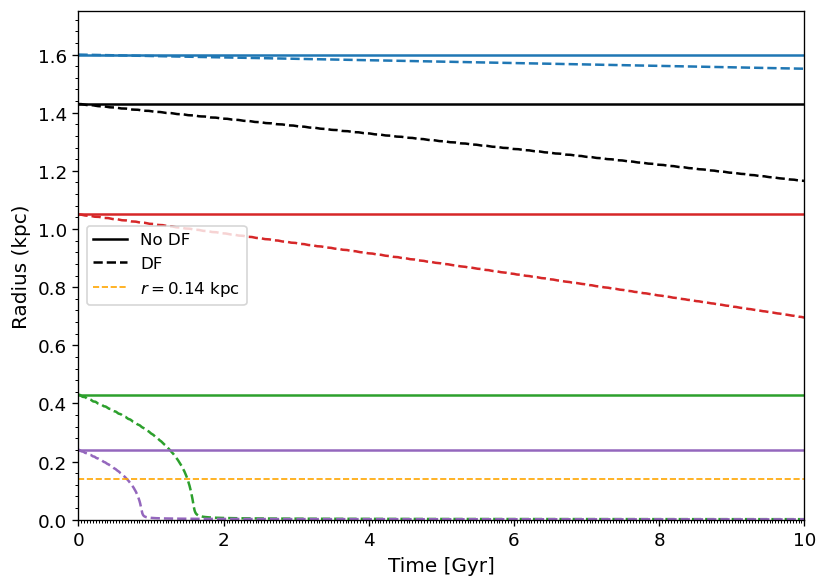

In [2]:
from astropy import units as u           #article : https://arxiv.org/abs/2510.00927
from astropy.constants import G
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, NFWPotential,vcirc
from galpy.orbit import Orbit
import numpy as np
import matplotlib.pyplot as plt

from colossus.halo import concentration
from colossus.halo import profile_nfw
from colossus.cosmology import cosmology
from matplotlib.ticker import AutoMinorLocator
cosmology.setCosmology('planck15')
plt.close('all')

M= 24.627e9           # Masse de la galaxie (Msol)
e=0
h=0.704
Mh=M*0.704
Redshift=0
c=concentration.concentration(Mh,'vir',Redshift,model ='prada12')
p_nfw= profile_nfw.NFWProfile(M=Mh, c=c, z=Redshift, mdef = 'vir')
Rvir = p_nfw.RDelta(Redshift, 'vir')/0.704    # en kpc
rs = p_nfw.par['rs']/0.704     # en kpc
A_NFW = np.log(1+c) - c/(1+c)
NFW_pot = NFWPotential(amp = M/A_NFW* u.Msun, a = rs * u.kpc)
a=np.sqrt(1+e)
print(A_NFW)

ts= np.linspace(0,10,1001)*u.Gyr 

GCs=Orbit([[1.6*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,1.6*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [1.05*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,1.05*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.43*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [1.43*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,1.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg]]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 


cdfs=[CDFF(GMs=0.37e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.82e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=3.63e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.32e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.78e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot)]  

G2=GCs
fig, ax = plt.subplots(figsize=(7,5), dpi=120) 
colors = ['tab:blue', 'tab:red', 'tab:green', 'tab:purple', 'black'] 
for i, (orbitDF, cd,o2) in enumerate(zip(GCs, cdfs,G2)): 
    col = colors[i % len(colors)] 
    o2.integrate(ts, NFW_pot, method='dop853_c')
    orbitDF.integrate(ts, NFW_pot+cd, method='dop853_c') 
    orbitDF.plot(color=col, linestyle='--', d1='t', d2='r', overplot=True,label="_nolegend_")
    o2.plot(color=col, linestyle='-', d1='t', d2='r', overplot=True,label="_nolegend_")
ax.plot([],[],color="black",linestyle="-",label="No DF")
ax.plot([],[],color="black",linestyle="--",label="DF")  
ax.axhline(0.14, color='orange', linewidth=1,linestyle='--', label=r"$r = 0.14$ kpc")
ax.set_xlabel("Time [Gyr]", fontsize=12) 
ax.set_ylabel("Radius (kpc)", fontsize=12) 
ax.set_xlim(0, 10) 
ax.set_ylim(0, 1.75) 
ax.legend(frameon=True, fancybox=True, shadow=None, fontsize=10) 
ax.tick_params(axis='both', labelsize=11) 
plt.tight_layout() 
#plt.savefig("tau1.png", dpi=300, bbox_inches="tight") 
plt.show()





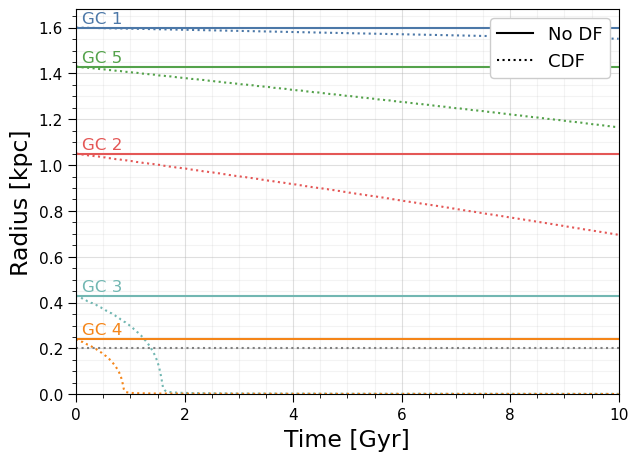

In [3]:
fig, ax = plt.subplots(figsize=(7,5))
colors = ['#4C78A8', '#E45756', '#72B7B2', '#F58518', '#54A24B']
for i, (orbitDF, cd, o2) in enumerate(zip(GCs, cdfs, G2)):
    col = colors[i % len(colors)]
    o2.integrate(ts, NFW_pot, method='dop853_c')
    orbitDF.integrate(ts, NFW_pot + cd, method='dop853_c')
    orbitDF.plot(color=col, linestyle=':', d1='t', d2='r', overplot=True, label="_nolegend_")
    o2.plot(color=col, linestyle='-', d1='t', d2='r', overplot=True, label="_nolegend_")
    ax.text(ts[0].value+0.1, o2.R(ts)[0]+0.02, "GC "+str(i+1), color=col, fontsize=12)
    
ax.plot([], [], color="black", linestyle="-", label="No DF")
ax.plot([], [], color="black", linestyle=":", label="CDF")
ax.axhline(0.2, color='grey', linewidth=1.5, linestyle=':')
ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Radius [kpc]", fontsize=17)
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.68)
ax.minorticks_on()
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.legend(frameon=True, loc="upper right", fontsize=13, framealpha=1)
#plt.tight_layout()
plt.savefig("1.png", dpi=300, bbox_inches="tight")
plt.show()

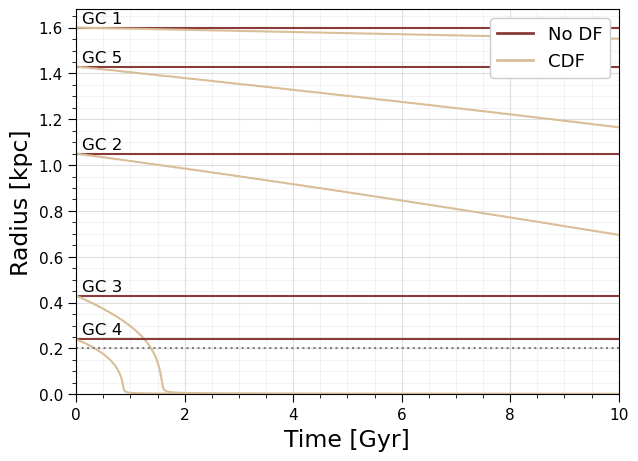

In [5]:
fig, ax = plt.subplots(figsize=(7,5))

for i, (orbitDF, cd, o2) in enumerate(zip(GCs, cdfs, G2)):
    o2.integrate(ts, NFW_pot, method='dop853_c')
    orbitDF.integrate(ts, NFW_pot + cd, method='dop853_c')
    o2.plot(color='#8B3A3A', linestyle='-', d1='t', d2='r',overplot=True, label="_nolegend_")
    orbitDF.plot(color='#D9BE98', linestyle='-', d1='t', d2='r', overplot=True, label="_nolegend_")

    ax.text(ts[0].value + 0.1, o2.R(ts)[0] + 0.02,f"GC {i+1}", color='black',fontsize=12)

ax.plot([], [], color='#8B3A3A', linestyle='-', linewidth=2, label='No DF')
ax.plot([], [], color='#D9BE98', linestyle='-', linewidth=2, label='CDF')
ax.axhline(0.2, color='grey', linewidth=1.5, linestyle=':')
ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Radius [kpc]", fontsize=17)
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.68)
ax.minorticks_on()
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.legend(frameon=True, loc="upper right", fontsize=13, framealpha=1)
plt.savefig("1.png", dpi=300, bbox_inches="tight")
plt.show()

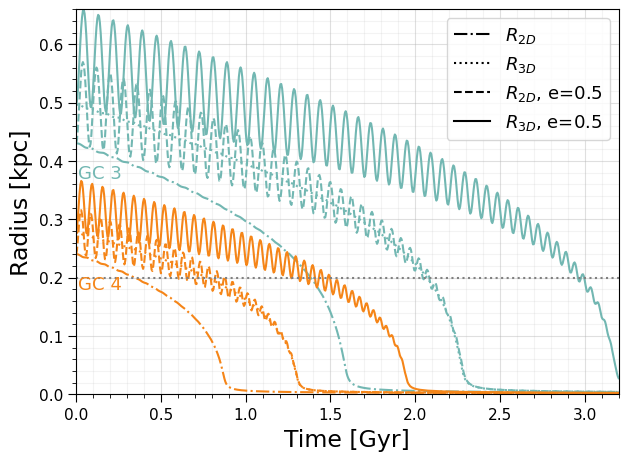

In [6]:
#%matplotlib widget
e=0.5
a=np.sqrt(1+e)
p=2/np.sqrt(3)
ts= np.linspace(0.,5,1001)*u.Gyr
GCs=Orbit([[0.43*u.kpc,0.*u.km/u.s,vcirc(NFW_pot,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,vcirc(NFW_pot,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 
GCs3=Orbit([[0.43*p*u.kpc,0.*u.km/u.s,vcirc(NFW_pot,0.43*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*p*u.kpc,0.*u.km/u.s,vcirc(NFW_pot,0.24*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s)

GCse=Orbit([[0.43*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.43*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.24*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 
GCse3=Orbit([[0.43*p*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.43*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],
          [0.24*p*u.kpc,0.*u.km/u.s,a*vcirc(NFW_pot,0.24*p*u.kpc)* u.km/u.s,0.*u.kpc,0.*u.km/u.s,0.*u.deg],]) #[R,vR,vT,z,vz,phi],ro=8(kpc) ,vo=220(km/s) 


cdfs=[CDFF(GMs=3.63e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),
      CDFF(GMs=1.32e5*u.Msun,rhm=0.01*u.kpc,dens=NFW_pot),      ]  
colors = ['#72B7B2', '#F58518']

fig, ax = plt.subplots(figsize=(7,5))
for i, (o1,o2,o3,o4,cd) in enumerate(zip(GCs,GCs3,GCse,GCse3,cdfs)):
    col = colors[i % len(colors)]
    o1.integrate(ts, NFW_pot + cd, method='dop853_c')
    o1.plot(color=col, linestyle='-.', d1='t', d2='r', overplot=True, label="_nolegend_")
    o2.integrate(ts, NFW_pot + cd, method='dop853_c')
    o2.plot(color=col, linestyle=':', d1='t', d2='r', overplot=True, label="_nolegend_")
    #plt.plot(ts.value,o2.r(ts), color="purple")
    o3.integrate(ts, NFW_pot + cd, method='dop853_c')
    o3.plot(color=col, linestyle='--', d1='t', d2='r', overplot=True, label="_nolegend_")
    o4.integrate(ts, NFW_pot + cd, method='dop853_c')
    o4.plot(color=col, linestyle='-', d1='t', d2='r', overplot=True, label="_nolegend_")
    ax.text(ts[0].value+0.01, o1.R(ts)[0]-0.06, "GC "+str(i+3), color=col,fontsize=13)

ax.plot([], [], color="black", linestyle="-.", label=rf"$R_{{2D}}$")
ax.plot([], [], color="black", linestyle=":", label=rf"$R_{{3D}}$")
ax.plot([], [], color="black", linestyle="--", label=rf"$R_{{2D}}$, e=0.5")
ax.plot([], [], color="black", linestyle="-", label=rf"$R_{{3D}}$, e=0.5")
ax.axhline(0.2, color='grey',linewidth=1.5, linestyle=':')
ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Radius [kpc]", fontsize=17)

ax.minorticks_on()


ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)

ax.set_xlim(0, 3.2)
ax.set_ylim(0, 0.66)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)


ax.tick_params(axis='both', labelsize=11)
ax.legend(frameon=True, fancybox=True, shadow=None, fontsize=13)
plt.savefig("tau2.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
print(rs,A_NFW)